# Supplementary Figure S14 — trace-element statistics

Standalone, function-free workflow for the crystal-level trace-element relationships and host-mineral comparisons. The scientific filtering, crystal aggregation, statistical tests, and plotted populations are unchanged.

## Shared setup for Figure S14

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.markers import MarkerStyle
from matplotlib.path import Path as MarkerPath
from matplotlib.patches import Patch
from scipy.stats import mannwhitneyu, rankdata
from statsmodels.stats.multitest import multipletests
from IPython.display import display

DECHERT_DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
USER_DATA_DIRECTORY = Path('/replace/with/your/folder/containing/the/three/supplemental/files')
DATA_DIRECTORY = DECHERT_DATA_DIRECTORY
# DATA_DIRECTORY = USER_DATA_DIRECTORY

PROJECT_ROOT = None
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if candidate.name == 'Nov6_AllFigures':
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start in Nov6_AllFigures or one of its figure folders.')

FIGURE_DIRECTORY = PROJECT_ROOT / 'Figure_S14_TE_Stats'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S14_TE_Stats_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

WORKBOOK_PATHS = {
    'S1': Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/GP_Combined/SEIMS_SEM_Raman_LAICPMS/Combining_All_Dechert_Data/Combining_All_Dechert_Data_S1_20261110.xlsx'),
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement}: required supplemental file not found: {path}')

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
FIGURE_WIDTH_IN = DOUBLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = MAXIMUM_RECOMMENDED_HEIGHT_IN
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300

PUBLICATION_FONT = 'Arial'
if PUBLICATION_FONT not in {entry.name for entry in font_manager.fontManager.ttflist}:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)

mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [PUBLICATION_FONT], 'font.size': BASE_TEXT_SIZE_PT,
    'axes.labelsize': BASE_TEXT_SIZE_PT, 'axes.titlesize': BASE_TEXT_SIZE_PT,
    'xtick.labelsize': BASE_TEXT_SIZE_PT, 'ytick.labelsize': BASE_TEXT_SIZE_PT,
    'legend.fontsize': BASE_TEXT_SIZE_PT, 'legend.title_fontsize': BASE_TEXT_SIZE_PT,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': True, 'axes.spines.right': True, 'axes.linewidth': 0.5,
    'lines.linewidth': 0.75, 'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'savefig.facecolor': 'white', 'savefig.transparent': False,
    'mathtext.fontset': 'custom', 'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic', 'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

SAMPLE_COLORS = {'74D': '#F4A261', '74A': '#D55E00', '75': '#56B4E9', '76A': '#0072B2'}
SAMPLE_LABELS = {'74D': 'B Middle', '74A': 'B Base', '75': 'G Top', '76A': 'G Middle'}
UNIT_MAP = {'74D': 'B', '74A': 'B', '75': 'G', '76A': 'G'}
PHASE_LABELS = {'plag': 'Plagioclase-hosted MI', 'pxy': 'Pyroxene-hosted MI'}

# Approved marker geometry from 00_Setup.
MARKER_SPANS_PT = {'plag': 6.0, 'pxy': 6.0}
MARKER_LETTERS = {'plag': 'o', 'pxy': 's'}
MARKER_PATHS = {}
SCATTER_STYLES = {}
for category, marker in MARKER_LETTERS.items():
    standard_marker = MarkerStyle(marker)
    marker_path = standard_marker.get_path().transformed(standard_marker.get_transform())
    bounds = marker_path.get_extents()
    vertices = marker_path.vertices.copy()
    vertices[:, 0] = (vertices[:, 0] - (bounds.x0 + bounds.x1) / 2) / bounds.width
    vertices[:, 1] = (vertices[:, 1] - (bounds.y0 + bounds.y1) / 2) / bounds.height
    normalized_path = MarkerPath(vertices, marker_path.codes)
    MARKER_PATHS[category] = normalized_path
    SCATTER_STYLES[category] = {
        'marker': normalized_path,
        's': (MARKER_SPANS_PT[category] - MINIMUM_LINE_WIDTH_PT) ** 2,
        'linewidths': MINIMUM_LINE_WIDTH_PT,
        'edgecolors': 'black',
    }

print('Figure directory:', FIGURE_DIRECTORY)
print('Publication font:', PUBLICATION_FONT_PATH)
print('Figure dimensions:', FIGURE_WIDTH_IN, 'x', FIGURE_HEIGHT_IN, 'in')

Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S14_TE_Stats
Publication font: /System/Library/Fonts/Supplemental/Arial.ttf
Figure dimensions: 7.25 x 7.8 in


## Figure S14-specific data preparation

The shared setup ends above. This figure reads only Supplement 1, sheet `MI_Hosts_Plag_Pxy`. Rows flagged `Discard_SIMS == yes`, matrix-glass rows, and non-plagioclase/non-pyroxene hosts are excluded. Multiple inclusions from one crystal are collapsed to one median value per trace element.

In [2]:
source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Hosts_Plag_Pxy')

te_columns = {}
for column in source.columns:
    match = re.fullmatch(r'\d+([A-Z][a-z]?)_TE_MI_mean', column)
    if match and match.group(1) not in ['Al', 'Si']:
        te_columns[match.group(1)] = column

if len(te_columns) != 23:
    raise ValueError(f'Expected 23 trace elements after excluding Al and Si; found {len(te_columns)}.')

data = source.copy()
data['sample_key'] = data['base_name'].astype('string').str.extract(r'^(74D|74A|76A|75)(?:_|$)', expand=False)
data['phase_key'] = data['mineral_phase'].astype('string').str.strip().str.casefold().replace({'opx': 'pxy'})
data['eruptive_unit'] = data['sample_key'].map(UNIT_MAP)
data['discard_sims'] = data['Discard_SIMS'].astype('string').str.strip().str.casefold().eq('yes').fillna(False)
data['matrix_glass'] = data['base_name'].astype('string').str.contains('MTX', case=False, na=False)

for column in te_columns.values():
    data[column] = pd.to_numeric(data[column], errors='coerce').replace([np.inf, -np.inf], np.nan)

retained_rows = (
    ~data['discard_sims']
    & ~data['matrix_glass']
    & data['sample_key'].isin(SAMPLE_COLORS)
    & data['phase_key'].isin(['plag', 'pxy'])
)
inclusions = data.loc[retained_rows].copy()
inclusions = inclusions.loc[inclusions[list(te_columns.values())].notna().any(axis=1)].copy()
inclusions['crystal_id'] = inclusions['base_name'].astype('string').str.extract(r'^(.+_C[^_]+)_MI', expand=False)

if inclusions['crystal_id'].isna().any():
    raise ValueError('At least one retained inclusion lacks a parseable crystal ID.')

crystal_keys = ['crystal_id', 'sample_key', 'eruptive_unit', 'phase_key']
crystals = inclusions.groupby(crystal_keys, as_index=False)[list(te_columns.values())].median()

population_summary = pd.DataFrame({
    'population': ['Retained inclusions', 'Retained crystals', 'G crystals', 'B crystals', 'Plagioclase-hosted crystals', 'Pyroxene-hosted crystals'],
    'count': [
        len(inclusions),
        len(crystals),
        int(crystals['eruptive_unit'].eq('G').sum()),
        int(crystals['eruptive_unit'].eq('B').sum()),
        int(crystals['phase_key'].eq('plag').sum()),
        int(crystals['phase_key'].eq('pxy').sum()),
    ],
})
display(population_summary)
print('Trace elements:', ', '.join(te_columns))

expected_counts = [87, 63, 33, 30, 29, 34]
if population_summary['count'].tolist() != expected_counts:
    raise ValueError('The retained Figure S14 population has changed; review the filtering before plotting.')

,population,count
0,Retained inclusions,87
1,Retained crystals,63
2,G crystals,33
3,B crystals,30
4,Plagioclase-hosted crystals,29
5,Pyroxene-hosted crystals,34


Trace elements: Rb, Sr, Y, Zr, Nb, Cs, Ba, La, Ce, Nd, Sm, Eu, Gd, Tb, Dy, Ho, Er, Tm, Yb, Hf, Ta, Th, U


## Figure S14 statistical comparisons

The G-versus-B comparison uses pooled crystal-level Mann–Whitney U tests. The plagioclase-versus-pyroxene comparison uses within-sample rank permutations that preserve the observed host counts in each sample. Benjamini–Hochberg correction is applied across all 23 elements in each comparison family.

In [3]:
elements = list(te_columns)
element_columns = list(te_columns.values())

unit_rows = []
for element, column in te_columns.items():
    g_values = crystals.loc[crystals['eruptive_unit'].eq('G'), column].dropna().to_numpy()
    b_values = crystals.loc[crystals['eruptive_unit'].eq('B'), column].dropna().to_numpy()

    test = mannwhitneyu(
        g_values,
        b_values,
        alternative='two-sided',
        method='asymptotic',
        use_continuity=True,
    )
    unit_rows.append({
        'element': element,
        'n_G': len(g_values),
        'n_B': len(b_values),
        'median_G_ppm': np.median(g_values),
        'median_B_ppm': np.median(b_values),
        'U': test.statistic,
        'p_raw': test.pvalue,
        'rank_biserial_G_vs_B': 2 * test.statistic / (len(g_values) * len(b_values)) - 1,
    })

unit_results = pd.DataFrame(unit_rows)
unit_results['p_fdr_bh'] = multipletests(unit_results['p_raw'], method='fdr_bh')[1]
unit_results['significant_fdr_05'] = unit_results['p_fdr_bh'].lt(0.05)

N_PERMUTATIONS = 199999
PERMUTATION_SEED = 20260908
sample_blocks = []
observed_rank_statistic = np.zeros(len(elements))
effect_denominator = 0.0

for sample_key, sample_block in crystals.groupby('sample_key', sort=True):
    values = sample_block[element_columns].to_numpy()
    is_plagioclase = sample_block['phase_key'].eq('plag').to_numpy()
    sample_size = len(sample_block)
    number_plagioclase = int(is_plagioclase.sum())
    number_pyroxene = sample_size - number_plagioclase

    ranks = rankdata(values, axis=0, method='average')
    centered_ranks = (ranks - (sample_size + 1) / 2) / (sample_size + 1)
    observed_rank_statistic += centered_ranks[is_plagioclase].sum(axis=0)
    effect_denominator += number_plagioclase * number_pyroxene / (sample_size + 1)
    sample_blocks.append((sample_size, number_plagioclase, centered_ranks))

random_generator = np.random.default_rng(PERMUTATION_SEED)
extreme_counts = np.zeros(len(elements), dtype=int)

for batch_start in range(0, N_PERMUTATIONS, 2000):
    batch_size = min(2000, N_PERMUTATIONS - batch_start)
    permuted_rank_statistics = np.zeros((batch_size, len(elements)))

    for sample_size, number_plagioclase, centered_ranks in sample_blocks:
        random_values = random_generator.random((batch_size, sample_size))
        selected_rows = np.argpartition(random_values, number_plagioclase - 1, axis=1)[:, :number_plagioclase]
        permuted_rank_statistics += centered_ranks[selected_rows].sum(axis=1)

    extreme_counts += (
        np.abs(permuted_rank_statistics) >= np.abs(observed_rank_statistic) - 1e-12
    ).sum(axis=0)

host_p_raw = (extreme_counts + 1) / (N_PERMUTATIONS + 1)
host_results = pd.DataFrame({
    'element': elements,
    'n_plag': int(crystals['phase_key'].eq('plag').sum()),
    'n_pxy': int(crystals['phase_key'].eq('pxy').sum()),
    'median_plag_ppm': [crystals.loc[crystals['phase_key'].eq('plag'), te_columns[element]].median() for element in elements],
    'median_pxy_ppm': [crystals.loc[crystals['phase_key'].eq('pxy'), te_columns[element]].median() for element in elements],
    'stratified_rank_statistic': observed_rank_statistic,
    'weighted_rank_biserial_plag_vs_pxy': 2 * observed_rank_statistic / effect_denominator,
    'p_raw': host_p_raw,
    'p_fdr_bh': multipletests(host_p_raw, method='fdr_bh')[1],
})
host_results['significant_fdr_05'] = host_results['p_fdr_bh'].lt(0.05)

significant_host_elements = host_results.loc[host_results['significant_fdr_05'], 'element'].tolist()
significant_unit_elements = unit_results.loc[unit_results['significant_fdr_05'], 'element'].tolist()

print('BH-significant host-phase elements:', significant_host_elements)
print('BH-significant G-versus-B elements:', significant_unit_elements)
display(host_results.loc[host_results['significant_fdr_05']])

EXPECTED_HOST_ELEMENTS = ['Zr', 'Nb', 'Ba', 'La', 'Ce', 'Tb', 'Ho', 'Hf']
if significant_host_elements != EXPECTED_HOST_ELEMENTS:
    raise ValueError('The significant host-phase element set has changed; review the statistics before plotting.')
if significant_unit_elements:
    raise ValueError('A G-versus-B comparison is now significant; review the statistics before plotting.')

BH-significant host-phase elements: ['Zr', 'Nb', 'Ba', 'La', 'Ce', 'Tb', 'Ho', 'Hf']
BH-significant G-versus-B elements: []


,element,n_plag,n_pxy,median_plag_ppm,median_pxy_ppm,stratified_rank_statistic,weighted_rank_biserial_plag_vs_pxy,p_raw,p_fdr_bh,significant_fdr_05
3,Zr,29,34,149.160352,97.590940,4.230677,0.585004,0.000080,0.000613,True
4,Nb,29,34,5.801752,5.047916,3.862388,0.534078,0.000280,0.001288,True
6,Ba,29,34,798.832804,741.201459,3.066735,0.424058,0.004770,0.018285,True
7,La,29,34,17.139183,20.476133,-6.254584,-0.864863,0.000005,0.000058,True
8,Ce,29,34,34.438237,39.376123,-5.807309,-0.803015,0.000005,0.000058,True
13,Tb,29,34,0.261828,0.233859,2.717446,0.375759,0.012820,0.036858,True
15,Ho,29,34,0.381200,0.344377,2.942089,0.406822,0.006575,0.021604,True
19,Hf,29,34,4.080283,3.227605,4.116642,0.569235,0.000120,0.000690,True


## Plot and export Figure S14

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S14_TE_Stats/Figure_S14_TE_Stats_Final/Figure_S14_TE_Stats.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S14_TE_Stats/Figure_S14_TE_Stats_Final/Figure_S14_TE_Stats.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S14_TE_Stats/Figure_S14_TE_Stats_Final/Figure_S14_TE_Stats.svg


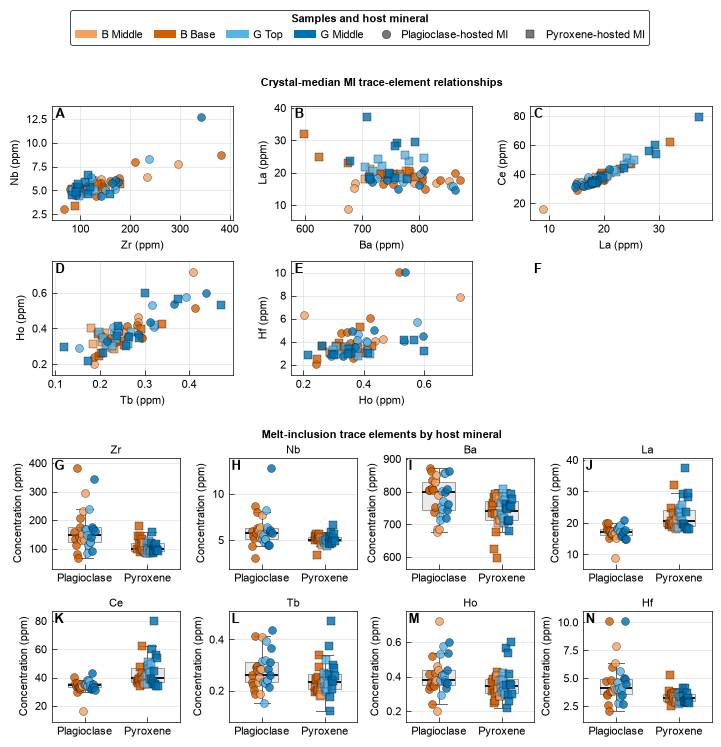

In [4]:
XY_RELATIONSHIPS = [('Zr', 'Nb'), ('Ba', 'La'), ('La', 'Ce'), ('Tb', 'Ho'), ('Ho', 'Hf')]
BOX_ELEMENTS = ['Zr', 'Nb', 'Ba', 'La', 'Ce', 'Tb', 'Ho', 'Hf']
PANEL_LETTERS = list('ABCDEFGHIJKLMN')

figure = plt.figure(figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN))
outer_grid = figure.add_gridspec(
    2, 1,
    height_ratios=[1.02, 1.0],
    left=0.075, right=0.985, bottom=0.065, top=0.855,
    hspace=0.31,
)
xy_grid = outer_grid[0].subgridspec(2, 3, wspace=0.32, hspace=0.36)
box_grid = outer_grid[1].subgridspec(2, 4, wspace=0.38, hspace=0.38)

xy_axes = []
for row in range(2):
    for column in range(3):
        xy_axes.append(figure.add_subplot(xy_grid[row, column]))

box_axes = []
for row in range(2):
    for column in range(4):
        box_axes.append(figure.add_subplot(box_grid[row, column]))

for panel_index, relationship in enumerate(XY_RELATIONSHIPS):
    axis = xy_axes[panel_index]
    x_element, y_element = relationship
    x_column = te_columns[x_element]
    y_column = te_columns[y_element]

    for sample_key, color in SAMPLE_COLORS.items():
        for phase in ['plag', 'pxy']:
            subset = crystals.loc[
                crystals['sample_key'].eq(sample_key) & crystals['phase_key'].eq(phase),
                [x_column, y_column],
            ].dropna()
            axis.scatter(
                subset[x_column],
                subset[y_column],
                facecolor=color,
                alpha=0.80,
                zorder=3,
                **SCATTER_STYLES[phase],
            )

    axis.set_xlabel(f'{x_element} (ppm)')
    axis.set_ylabel(f'{y_element} (ppm)')
    axis.grid(True, color='#D9D9D9', linewidth=0.4)
    axis.set_axisbelow(True)
    axis.margins(x=0.08, y=0.12)
    axis.text(
        0.02, 0.98, PANEL_LETTERS[panel_index],
        transform=axis.transAxes,
        ha='left', va='top',
        fontsize=PANEL_LABEL_SIZE_PT,
        fontweight='bold',
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.80, 'pad': 0.3},
        zorder=10,
    )
    for spine in axis.spines.values():
        spine.set_visible(True)

blank_axis = xy_axes[5]
blank_axis.set_axis_off()
blank_axis.text(
    0.02, 0.98, PANEL_LETTERS[5],
    transform=blank_axis.transAxes,
    ha='left', va='top',
    fontsize=PANEL_LABEL_SIZE_PT,
    fontweight='bold',
)

for panel_offset, element in enumerate(BOX_ELEMENTS):
    axis = box_axes[panel_offset]
    value_column = te_columns[element]
    plagioclase_values = crystals.loc[crystals['phase_key'].eq('plag'), value_column].dropna().to_numpy()
    pyroxene_values = crystals.loc[crystals['phase_key'].eq('pxy'), value_column].dropna().to_numpy()

    boxplot = axis.boxplot(
        [plagioclase_values, pyroxene_values],
        positions=[0, 1],
        widths=0.52,
        patch_artist=True,
        showfliers=False,
        medianprops={'color': 'black', 'linewidth': 1.3},
        boxprops={'facecolor': '#D9D9D9', 'edgecolor': '#555555', 'linewidth': 0.75},
        whiskerprops={'color': '#666666', 'linewidth': 0.7},
        capprops={'color': '#666666', 'linewidth': 0.7},
    )
    for box in boxplot['boxes']:
        box.set_alpha(0.55)

    for phase_index, phase in enumerate(['plag', 'pxy']):
        phase_subset = crystals.loc[
            crystals['phase_key'].eq(phase),
            ['crystal_id', 'sample_key', value_column],
        ].dropna().sort_values(['sample_key', 'crystal_id'], kind='stable')
        if len(phase_subset) > 1:
            horizontal_offsets = np.linspace(-0.16, 0.16, len(phase_subset))
        else:
            horizontal_offsets = np.array([0.0])

        for horizontal_offset, (_, row_values) in zip(horizontal_offsets, phase_subset.iterrows()):
            sample_key = row_values['sample_key']
            concentration = row_values[value_column]
            axis.scatter(
                phase_index + horizontal_offset,
                concentration,
                facecolor=SAMPLE_COLORS[sample_key],
                alpha=0.82,
                zorder=3,
                **SCATTER_STYLES[phase],
            )

    axis.set_title(element, pad=3)
    axis.set_xticks([0, 1], ['Plagioclase', 'Pyroxene'])
    axis.set_ylabel('Concentration (ppm)')
    axis.set_xlim(-0.52, 1.52)
    axis.grid(True, axis='y', color='#D9D9D9', linewidth=0.4)
    axis.set_axisbelow(True)
    axis.margins(y=0.12)
    axis.text(
        0.02, 0.98, PANEL_LETTERS[panel_offset + 6],
        transform=axis.transAxes,
        ha='left', va='top',
        fontsize=PANEL_LABEL_SIZE_PT,
        fontweight='bold',
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.80, 'pad': 0.3},
        zorder=10,
    )
    for spine in axis.spines.values():
        spine.set_visible(True)

sample_handles = [
    Patch(facecolor=SAMPLE_COLORS[sample], edgecolor='none', label=SAMPLE_LABELS[sample])
    for sample in ['74D', '74A', '75', '76A']
]
phase_handles = [
    Line2D(
        [], [], linestyle='none',
        marker=MARKER_PATHS[phase],
        markerfacecolor='#777777',
        markeredgecolor='black',
        markeredgewidth=MINIMUM_LINE_WIDTH_PT,
        markersize=MARKER_SPANS_PT[phase],
        label=PHASE_LABELS[phase],
    )
    for phase in ['plag', 'pxy']
]
legend = figure.legend(
    handles=sample_handles + phase_handles,
    title='Samples and host mineral',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.985),
    ncol=6,
    frameon=True,
    facecolor='white',
    edgecolor='black',
    framealpha=1.0,
    handletextpad=0.4,
    columnspacing=1.0,
)
legend.get_title().set_fontweight('bold')
legend.get_frame().set_linewidth(0.5)

figure.text(
    (xy_axes[0].get_position().x0 + xy_axes[2].get_position().x1) / 2,
    max(axis.get_position().y1 for axis in xy_axes[:3]) + 0.022,
    'Crystal-median MI trace-element relationships',
    ha='center', va='bottom', fontweight='bold',
)
figure.text(
    (box_axes[0].get_position().x0 + box_axes[3].get_position().x1) / 2,
    max(axis.get_position().y1 for axis in box_axes[:4]) + 0.022,
    'Melt-inclusion trace elements by host mineral',
    ha='center', va='bottom', fontweight='bold',
)

pdf_path = OUTPUT_DIRECTORY / 'Figure_S14_TE_Stats.pdf'
png_path = OUTPUT_DIRECTORY / 'Figure_S14_TE_Stats.png'
svg_path = OUTPUT_DIRECTORY / 'Figure_S14_TE_Stats.svg'
figure.savefig(pdf_path, format='pdf', facecolor='white', transparent=False)
figure.savefig(png_path, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(svg_path, format='svg', facecolor='white', transparent=False)

print('Saved:', pdf_path)
print('Saved:', png_path)
print('Saved:', svg_path)
plt.show()